<h1 style="background: linear-gradient(to right, #395761, #7799B6);
           color: white;
           padding: 22px;
           border-left: 10px solid #CEEB13;
           text-align: center;
           font-family: 'Roboto Mono', Menlo, 'Courier New', monospace;
           font-weight: 600;">
  Inference-Time Scaling: Sampling and Self-Consistency
</h1>


The model's weights are frozen for this whole notebook. Everything we change happens at inference time: how we prompt, how we pick each token, and how many answers we generate before committing to one. These are the cheapest reasoning improvements there are, they work on any model, and they set up the ideas (sampling several chains, scoring them) that reinforcement learning is built from.

By the end of this notebook you will:

1. See what inference-time scaling means and what it costs,
2. Watch a one-sentence change to the prompt turn a bare guess into a worked solution,
3. Add temperature scaling and top-p sampling to the decoding loop from the text generation notebook,
4. Implement self-consistency, which samples several solutions and lets them vote,
5. Measure each step with the MATH-500 harness from the math verifier notebook.

Every function that changes how the model decodes is written here. The charts come from `reasoning_utils/plots.py`.

## `Step 1`: Three levers that need no training

A reasoning model is usually trained. But some of the gain can be had with the model you already have, by spending more tokens per problem instead of more gradient steps. That trade, tokens for accuracy at inference time, is called **inference-time scaling** (or test-time compute).

<div align="center"><img src="assets/inference-time-scaling.svg" alt="One frozen pretrained LLM fans out into three methods: ask for the work, sample several chains and vote, critique and revise; each has a token cost and all are scored by the same math verifier" width="1000"/></div>

| Lever | What changes | Cost per problem |
|---|---|---|
| ask for the work | one sentence in the prompt | one longer chain |
| **sample and vote** | the token-picking rule, run several times | about *n* chains |
| critique and revise | a second pass over the model's own answer | a chain plus a rewrite |

This notebook covers the first two. The third has its own notebook. The judge is the same for all of them: the verifier and `evaluate_math` from the previous notebook, so every number here is directly comparable to the base model's greedy score.

## `Step 2`: Setup

The same base model, [Qwen3-0.6B-Base](https://huggingface.co/Qwen/Qwen3-0.6B-Base), compiled because this notebook generates a lot of text. Compilation happens on the first generation, so the first cell that generates stalls for a while before any token appears, and the next generations are fast.

In [1]:
from collections import Counter

import torch

from reasoning_utils import (
    MATH_PROMPT,
    KVCache,
    evaluate_math,
    extract_final_answer,
    generate_text,
    get_device,
    grade,
    load_math500,
    load_qwen3,
    render_math_prompt,
)
from reasoning_utils.plots import (
    plot_accuracy_comparison,
    plot_accuracy_vs_samples,
    plot_temperature_effect,
    plot_top_p,
)

device = get_device()
model, tokenizer = load_qwen3("base", device=device, compile=True)

device: cuda (NVIDIA L40S)


A running example for the whole notebook: a word problem with a single numeric answer, 126, which the base model gets wrong when it answers directly. `generate_text` is the greedy loop from the text generation notebook; `stream=True` prints each token as the model produces it.

In [2]:
problem = "A rectangle's length is 4 more than twice its width. Its perimeter is 50. What is its area?"
answer = "126"

prompt = render_math_prompt(problem, MATH_PROMPT)
print(prompt)

You are a helpful math assistant.
Answer the question and write the final result on a new line as:
\boxed{ANSWER}

Question:
A rectangle's length is 4 more than twice its width. Its perimeter is 50. What is its area?

Answer:


In [3]:
response = generate_text(model, tokenizer, prompt, device, max_new_tokens=400, stream=True)

 \boxed{120}

In [4]:
grade(extract_final_answer(response), answer)

False

## `Step 3`: Ask for the work

The model jumped straight to a number. The prompt template asked for an answer, so it gave one, and a 0.6B model guessing a two-step word problem in one token is mostly wrong. Appending one sentence changes what kind of document the model believes it is completing:

<div align="center"><img src="assets/chain-of-thought.svg" alt="The same rectangle problem sent twice: the plain prompt gets a bare boxed 120, which is wrong; the prompt with the sentence show your work step by step gets four worked steps and a boxed 126, which is right" width="1000"/></div>

In [5]:
COT_PROMPT = MATH_PROMPT + " Show your work step by step."

prompt_cot = render_math_prompt(problem, COT_PROMPT)
print(prompt_cot)

You are a helpful math assistant.
Answer the question and write the final result on a new line as:
\boxed{ANSWER}

Question:
A rectangle's length is 4 more than twice its width. Its perimeter is 50. What is its area?

Answer: Show your work step by step.


In [6]:
response_cot = generate_text(model, tokenizer, prompt_cot, device, max_new_tokens=400, stream=True)

 Let's solve the problem step by step.

**Step 1: Define the variables**
Let \( w \) be the width of the rectangle.
Then, the length \( l \) is \( 2w + 4 \).

**Step 2: Write the formula for the perimeter**
The perimeter \( P \) of a rectangle is given by:
\[ P = 2(l + w) \]

**Step 3: Substitute the given perimeter**
We know the perimeter is 50, so:
\[ 2(l + w) = 50 \]

**Step 4: Substitute the expression for \( l \)**
\[ 2((2w + 4) + w) = 50 \]
\[ 2(3w + 4) = 50 \]

**Step 5: Simplify and solve for \( w \)**
\[ 6w + 8 = 50 \]
\[ 6w = 42 \]
\[ w = 7 \]

**Step 6: Find the length \( l \)**
\[ l = 2w + 4 \]
\[ l = 2(7) + 4 \]
\[ l = 14 + 4 \]
\[ l = 18 \]

**Step 7: Calculate the area \( A \)**
The area \( A \) of a rectangle is given by:
\[ A = l \times w \]
\[ A = 18 \times 7 \]
\[ A = 126 \]

**Final Answer:**
\boxed{126}

In [7]:
grade(extract_final_answer(response_cot), answer)

True

This is **chain-of-thought prompting**: the model writes the intermediate steps as tokens, and each step conditions the next, so the final number is computed rather than guessed. It costs more tokens per answer, which is the trade at the heart of this notebook. Nothing about the model changed. The capability was there; the prompt only made the model use it.

> **Try it.** Replace the sentence in `COT_PROMPT` with your own wording, or put it before the question instead of after `Answer:`. Base models are sensitive to such details (the previous notebook measured this). Which placements still produce a worked solution?

## `Step 4`: Where randomness comes from

So far every answer has been deterministic: at each step we took the token with the highest logit. To get *several different* solutions to the same problem we need to pick tokens differently. The place to intervene is the one row of logits that scores the next token, so we go back to that row for a short prompt.

In [8]:
text = "The opposite of hot is"
input_ids = torch.tensor(tokenizer.encode(text), device=device).unsqueeze(0)

with torch.inference_mode():
    logits = model(input_ids)[:, -1].float()
print(logits.shape)

torch.Size([1, 151936])


In [9]:
next_id = torch.argmax(logits, dim=-1).item()
print(next_id, "-->", repr(tokenizer.decode([next_id])))

9255 --> ' cold'


### Temperature

A softmax turns logits into probabilities. Dividing the logits by a **temperature** first changes how peaked that distribution is: below 1 the top token takes almost all the mass, above 1 the mass spreads out. The argmax never changes, only how much the model "prefers" it.

<div align="center"><img src="assets/temperature.gif" alt="Animation: the probabilities of the ten most likely next tokens after a short prompt, reshaping as the temperature sweeps from 0.2 up to 3.0 and back" width="900"/></div>

In [10]:
def scale_by_temperature(logits, temperature):
    if temperature <= 0:
        raise ValueError("temperature must be positive")
    return logits / temperature

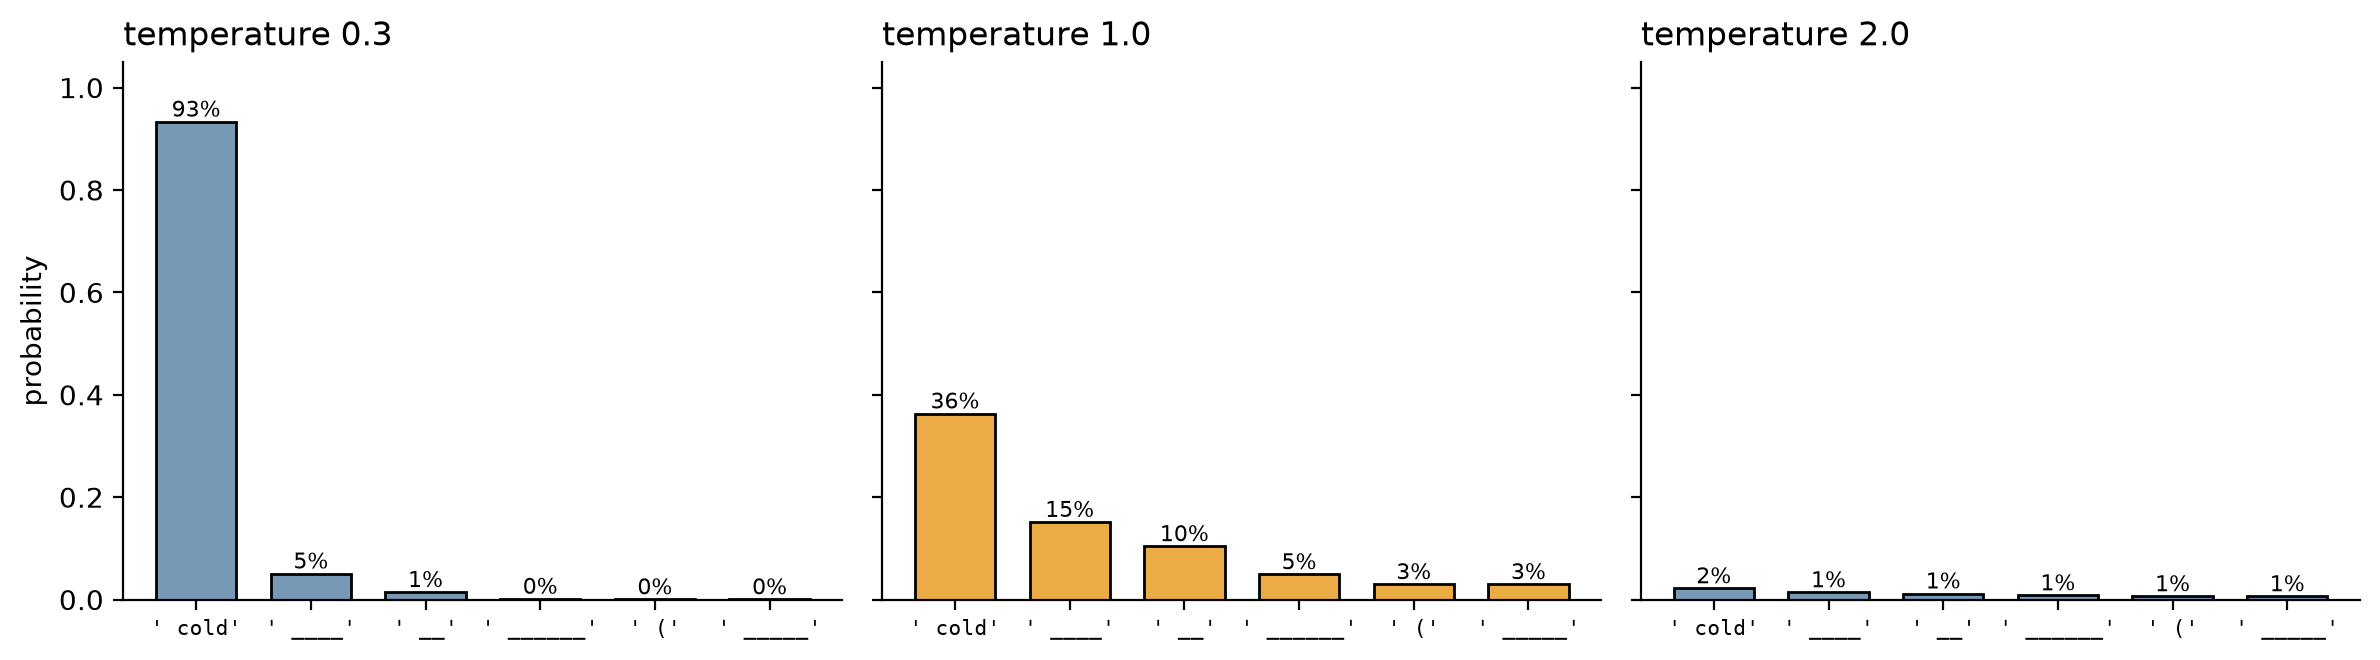

In [11]:
plot_temperature_effect(logits, tokenizer, temperatures=(0.3, 1.0, 2.0))

Two things to notice. The runner-up tokens are blanks (`' ____'`): the base model has seen a great many fill-in-the-blank worksheets and thinks it may be writing one. And at temperature 2 the top token has only a few percent of the mass, so most draws would be something else.

### Sampling

**Sampling** means drawing the next token from this distribution instead of taking its maximum. [`torch.multinomial`](https://docs.pytorch.org/docs/stable/generated/torch.multinomial.html) does the draw. At temperature 1 the probabilities are the plain softmax:

In [12]:
probs = torch.softmax(scale_by_temperature(logits, 1.0), dim=-1)
print(probs.sum())
print(probs.max())

tensor(1.0000, device='cuda:0')
tensor(0.3631, device='cuda:0')


In [13]:
torch.manual_seed(0)
sampled = torch.multinomial(probs, num_samples=1)
print(sampled.item(), "-->", repr(tokenizer.decode([sampled.item()])))

9255 --> ' cold'


One draw tells us little. A thousand draws show what each temperature actually produces, so here is a small helper that draws many times and counts the most frequent tokens:

In [14]:
def count_samples(probs, tokenizer, num_samples=1000, k=5):
    draws = torch.multinomial(probs, num_samples=num_samples, replacement=True)
    counts = torch.bincount(draws[0], minlength=probs.shape[-1])
    for i in torch.topk(counts, k).indices.tolist():
        print(f"{tokenizer.decode([i])!r}: {counts[i].item()}x")

In [15]:
torch.manual_seed(0)
count_samples(torch.softmax(scale_by_temperature(logits, 0.3), dim=-1), tokenizer)

' cold': 935x
' ____': 52x
' __': 10x
' ______': 3x
'!': 0x


In [16]:
torch.manual_seed(0)
count_samples(torch.softmax(scale_by_temperature(logits, 1.0), dim=-1), tokenizer)

' cold': 379x
' ____': 150x
' __': 92x
' ______': 51x
' (': 43x


In [17]:
torch.manual_seed(0)
count_samples(torch.softmax(scale_by_temperature(logits, 2.0), dim=-1), tokenizer)

' cold': 17x
' ____': 16x
' __': 12x
' ______': 11x
' (': 8x


At temperature 2 the draws land on tokens that make no sense after "The opposite of hot is". High temperature buys diversity by letting in the long tail of the vocabulary, and the tail is where nonsense lives. The next step removes the tail.

## `Step 5`: Cut the tail with top-p

**Top-p sampling** (also called nucleus sampling) keeps only the smallest set of tokens whose probabilities add up to at least *p*, and samples from those. A toy distribution over ten tokens is easier to look at than 151 thousand, so we build the filter on that first.

In [18]:
toy_logits = torch.tensor([0.1, 2.0, -1.0, 1.5, -0.5, 0.3, -2.0, -1.2, 0.8, -3.0])
toy_probs = torch.softmax(toy_logits, dim=-1)
print(toy_probs)

tensor([0.0614, 0.4102, 0.0204, 0.2488, 0.0337, 0.0749, 0.0075, 0.0167, 0.1236,
        0.0028])


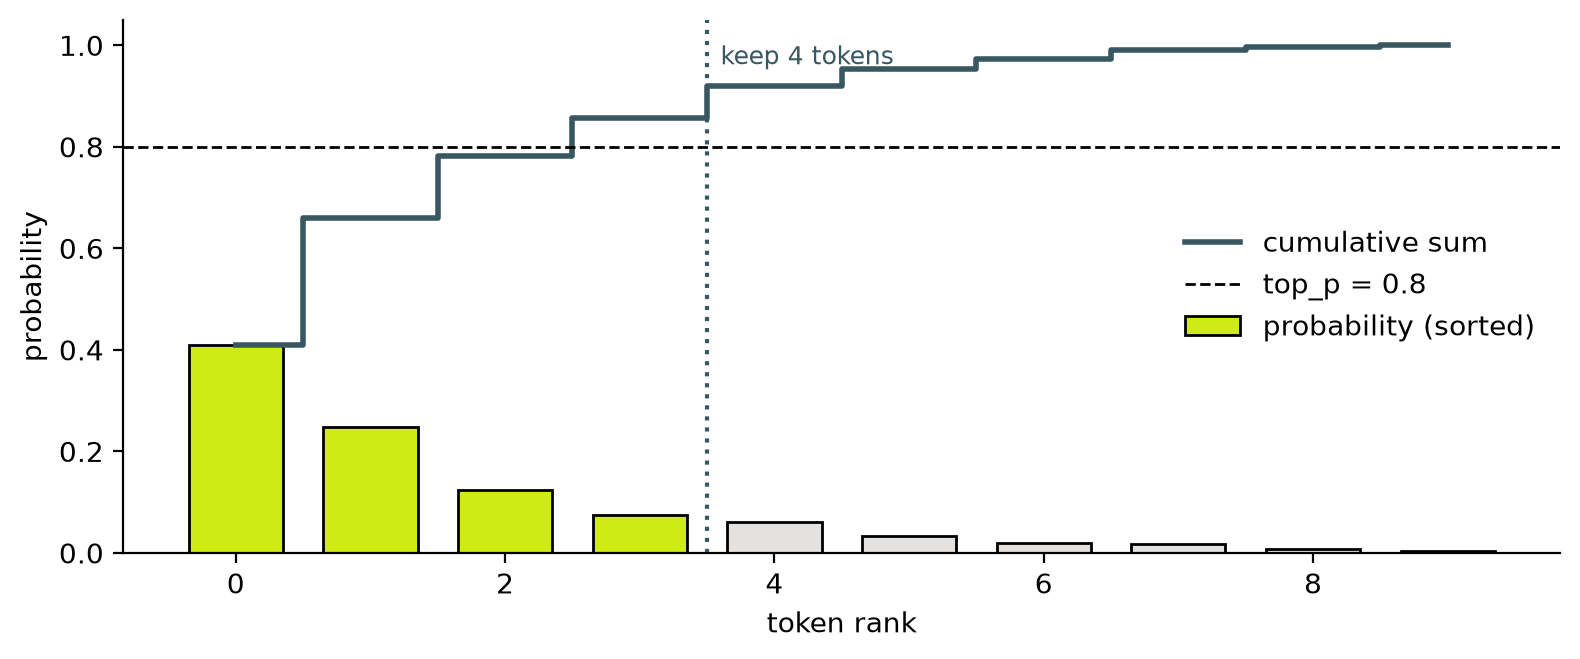

In [19]:
plot_top_p(toy_probs, top_p=0.8)

The chart is the whole procedure. Sort the probabilities from high to low, take their running sum, and draw a line at *p*. Everything to the left of where the running sum crosses the line is kept. In code it is four tensor operations.

In [20]:
# 1. sort by descending probability and take the cumulative sum
sorted_probs, sorted_idx = torch.sort(toy_probs, descending=True)
cumulative = torch.cumsum(sorted_probs, dim=-1)
print(sorted_probs)
print(cumulative)

tensor([0.4102, 0.2488, 0.1236, 0.0749, 0.0614, 0.0337, 0.0204, 0.0167, 0.0075,
        0.0028])
tensor([0.4102, 0.6590, 0.7826, 0.8575, 0.9189, 0.9526, 0.9730, 0.9897, 0.9972,
        1.0000])


In [21]:
# 2. keep a token while the mass of the tokens ranked above it is below top_p
top_p = 0.8
keep = (cumulative - sorted_probs) < top_p
print(keep)
print("tokens kept:", keep.sum().item())

tensor([ True,  True,  True,  True, False, False, False, False, False, False])
tokens kept: 4


Checking the mass *before* each token, rather than the cumulative sum that includes it, means the token that crosses the threshold is kept too. That is the common convention and it guarantees at least one token survives even for a tiny *p*.

In [22]:
# 3. zero out the rest and map back to vocabulary order
kept_sorted = torch.where(keep, sorted_probs, torch.zeros_like(sorted_probs))
filtered = torch.zeros_like(toy_probs).scatter(0, sorted_idx, kept_sorted)
print(filtered)

tensor([0.0000, 0.4102, 0.0000, 0.2488, 0.0000, 0.0749, 0.0000, 0.0000, 0.1236,
        0.0000])


In [23]:
# 4. renormalize so the survivors sum to 1
renormalized = filtered / filtered.sum()
print(renormalized)
print(renormalized.sum())

tensor([0.0000, 0.4784, 0.0000, 0.2901, 0.0000, 0.0874, 0.0000, 0.0000, 0.1441,
        0.0000])
tensor(1.0000)


<div align="center"><img src="assets/top-p.gif" alt="Animation: the ten toy probabilities sorted high to low with their cumulative sum; as p sweeps from 0.3 to 1.0 and back, the dashed threshold moves and the number of kept tokens, drawn in yellow, grows and shrinks" width="900"/></div>

The same four operations as one function, written for a batch of rows so that it can sit inside the decoding loop, where the logits have shape `(batch, vocabulary)`:

In [24]:
def top_p_filter(probs, top_p):
    if top_p is None or top_p >= 1.0:
        return probs

    # sort by descending probability and take the cumulative sum
    sorted_probs, sorted_idx = torch.sort(probs, dim=-1, descending=True)
    cumulative = torch.cumsum(sorted_probs, dim=-1)

    # keep a token while the mass of the tokens ranked above it is below top_p,
    # so the token that crosses the threshold is kept too
    keep = (cumulative - sorted_probs) < top_p

    # zero out the rest and map back to vocabulary order
    kept_sorted = torch.where(keep, sorted_probs, torch.zeros_like(sorted_probs))
    filtered = torch.zeros_like(probs).scatter(-1, sorted_idx, kept_sorted)

    # renormalize so the survivors sum to 1
    return filtered / filtered.sum(dim=-1, keepdim=True)

In [25]:
print(top_p_filter(toy_probs.unsqueeze(0), top_p=0.8))

tensor([[0.0000, 0.4784, 0.0000, 0.2901, 0.0000, 0.0874, 0.0000, 0.0000, 0.1441,
         0.0000]])


Temperature and top-p are usually used together: the temperature sets how adventurous the draw is, top-p sets how far into the tail it may go. Back on the real distribution, the same thousand draws at temperature 2 look very different once the tail is gone.

In [26]:
probs = torch.softmax(scale_by_temperature(logits, 2.0), dim=-1)

for p in [None, 0.9, 0.5]:
    torch.manual_seed(0)
    print("top_p =", p, "eligible tokens:", int((top_p_filter(probs, p) > 0).sum()))
    count_samples(top_p_filter(probs, p), tokenizer)
    print()

top_p = None eligible tokens: 151936
' cold': 17x
' ____': 16x
' __': 12x
' ______': 11x
' (': 8x

top_p = 0.9 eligible tokens: 33755
' cold': 30x
' ____': 15x
' ___': 10x
' ______': 8x
' (': 8x

top_p = 0.5 eligible tokens: 2173
' cold': 48x
' ____': 29x
' __': 21x
' ______': 20x
' _____': 18x



## `Step 6`: Sampling inside the decoding loop

Everything above acts on a single row of logits, which is exactly what the decoding loop holds at every step. Here is `generate_tokens` from the text generation notebook with one new block: when the temperature is 0 the line is the familiar argmax, otherwise the logits are scaled, turned into probabilities, filtered, and drawn from.

<div align="center"><img src="assets/sampling-pipeline.svg" alt="One row of logits flows through divide by temperature, softmax, top-p filter, and multinomial draw to the next token; a dashed bypass labeled temperature 0 goes straight from the logits through argmax" width="1000"/></div>

In [27]:
@torch.inference_mode()
def generate_tokens(model, token_ids, max_new_tokens, eos_token_id=None, temperature=0.0, top_p=None):
    model.eval()
    cache = KVCache(n_layers=len(model.layers))
    model.reset_kv_cache()

    logits = model(token_ids, cache=cache)[:, -1]
    for step in range(max_new_tokens):
        if temperature == 0.0:
            next_token = torch.argmax(logits, dim=-1, keepdim=True)  # greedy decoding, as before
        else:
            # NEW: scale the logits, turn them into probabilities, drop the tail, draw a token
            probs = torch.softmax(scale_by_temperature(logits.float(), temperature), dim=-1)
            probs = top_p_filter(probs, top_p)
            next_token = torch.multinomial(probs, num_samples=1)

        if eos_token_id is not None and torch.all(next_token == eos_token_id):
            break
        yield next_token
        if step + 1 < max_new_tokens:
            logits = model(next_token, cache=cache)[:, -1]

The wrapper that turns a prompt string into a completion string gains the same two arguments and passes them through. With `stream=True` it prints every token as soon as the loop yields it.

In [28]:
def generate_text(
    model, tokenizer, prompt, device, max_new_tokens=512, stream=False, temperature=0.0, top_p=None
):
    token_ids = torch.tensor(tokenizer.encode(prompt), device=device).unsqueeze(0)

    generated = []
    for token in generate_tokens(model, token_ids, max_new_tokens, tokenizer.eos_token_id, temperature, top_p):
        token_id = token.squeeze(0).item()
        generated.append(token_id)
        if stream:
            print(tokenizer.decode([token_id]), end="", flush=True)
    return tokenizer.decode(generated)

Defining these two functions here replaces the greedy versions imported at the top; with the default `temperature=0.0` they behave exactly as before. One sampled solution to our problem, with the step-by-step prompt:

In [29]:
torch.manual_seed(1)
response = generate_text(
    model, tokenizer, prompt_cot, device, max_new_tokens=600, stream=True, temperature=0.8, top_p=0.9
)

 First, we can set up the equation for the perimeter of the rectangle:
Perimeter = 2(length + width)

We know that the length is 4 more than twice the width, so we can express the length in terms of the width:
length = 2 * width + 4

Now we can substitute this expression for the length into the perimeter equation:
50 = 2((2 * width + 4) + width)

Next, we simplify the equation:
50 = 2(2 * width + 4 + width)
50 = 2(3 * width + 4)
50 = 6 * width + 8

Now, we solve for the width:
50 - 8 = 6 * width
42 = 6 * width
width = 42 / 6
width = 7

Now that we know the width, we can find the length:
length = 2 * width + 4
length = 2 * 7 + 4
length = 14 + 4
length = 18

Finally, we can find the area of the rectangle:
Area = length * width
Area = 18 * 7
Area = 126

So the area of the rectangle is \boxed{126} square units.

Run that cell again and the solution changes. Five more samples, keeping only the final answer of each:

In [30]:
torch.manual_seed(1)
for i in range(5):
    text = generate_text(model, tokenizer, prompt_cot, device, max_new_tokens=600, temperature=0.8, top_p=0.9)
    print(f"sample {i + 1}: {extract_final_answer(text)!r}")

sample 1: '126'
sample 2: '126'
sample 3: '126'
sample 4: '126'
sample 5: '126'


Different routes, mostly the same destination. The seed makes a run reproducible on one machine; expect different draws on different hardware or library versions.

> **Try it.** Rerun the cell with `temperature=1.5` and then with `top_p=None`. At what point do the chains stop reaching an answer at all? Then try `temperature=0.3`: how similar do the five chains become?

## `Step 7`: Self-consistency, or let the chains vote

If five sampled solutions mostly agree, their majority answer is more reliable than any single one of them. A wrong chain tends to be wrong in its own way, so wrong answers scatter while the right answer repeats. That observation is **self-consistency**: sample several chains, extract each final answer, and keep the one with the most votes.

<div align="center"><img src="assets/self-consistency.gif" alt="Animation: one problem is sampled five times, each chain's boxed answer is extracted, the answers are tallied, and 126 wins four votes to one" width="900"/></div>

```mermaid
flowchart LR
    P[prompt with step by step] --> S1[sample chain 1]
    P --> S2[sample chain 2]
    P --> S3[sample chain n]
    S1 --> E1[extract answer]
    S2 --> E2[extract answer]
    S3 --> E3[extract answer]
    E1 --> V{vote}
    E2 --> V
    E3 --> V
    V --> F[most common answer]
    style P fill:#C3D6E7,stroke:#000
    style V fill:#CEEB13,stroke:#000
    style F fill:#ECAC45,stroke:#000
```

The vote is a `Counter`, with one detail the verifier makes easy: two chains that write `126` and `126.0`, or `7/2` and `\frac{7}{2}`, are the same vote, so an answer joins an existing group when `grade` says the two are equivalent. The tally is keyed by the first spelling seen in each group, and a tie goes to the group that appeared first.

In [31]:
def majority_vote(answers):
    votes = Counter()
    for answer in answers:
        for seen in votes:
            if answer == seen or grade(answer, seen):
                votes[seen] += 1
                break
        else:
            votes[answer] += 1
    return votes.most_common(1)[0][0], votes

In [32]:
print(majority_vote(["126", "126.0", "32", r"\frac{252}{2}", "32"]))

('126', Counter({'126': 3, '32': 2}))


`self_consistency` wraps the sampling around the vote: generate `n_samples` completions, extract each final answer, and return everything so that the chains can be inspected afterwards.

In [33]:
def self_consistency(
    model, tokenizer, prompt, device, n_samples=5, temperature=0.8, top_p=0.9, max_new_tokens=1024, verbose=False
):
    completions, answers = [], []
    for i in range(n_samples):
        text = generate_text(
            model, tokenizer, prompt, device, max_new_tokens=max_new_tokens, temperature=temperature, top_p=top_p
        )
        completions.append(text)
        answers.append(extract_final_answer(text))
        if verbose:
            print(f"sample {i + 1}/{n_samples}: {answers[-1]!r}")

    final, votes = majority_vote(answers)
    return {"completions": completions, "answers": answers, "votes": votes, "final": final}

In [34]:
torch.manual_seed(3)
vote = self_consistency(
    model, tokenizer, prompt_cot, device, n_samples=5, temperature=0.8, top_p=0.9, max_new_tokens=600, verbose=True
)

sample 1/5: '126'
sample 2/5: ''
sample 3/5: '126'
sample 4/5: '126'
sample 5/5: '126'


In [35]:
print(vote["votes"])
print(vote["final"])
print(grade(vote["final"], answer))

Counter({'126': 4, '': 1})
126
True


Four chains reached 126 and one ran out of its 600-token budget before boxing anything, so it cast an empty vote; the majority carried. That is the vote doing its job, and it is also a reminder that the seed only makes a run repeatable on one machine: different hardware or library versions draw differently.

Voting needs something to vote on. Without the step-by-step sentence, whether a sampled chain works the problem out or blurts a number is itself a matter of chance. The length of each chain tells you which happened:

In [36]:
torch.manual_seed(1)
vote_bare = self_consistency(model, tokenizer, prompt, device, n_samples=5, temperature=0.8, top_p=0.9, max_new_tokens=600)

for text, a in zip(vote_bare["completions"], vote_bare["answers"]):
    print(f"answer {a!r} from a chain of {len(tokenizer.encode(text))} tokens")
print(vote_bare["final"], grade(vote_bare["final"], answer))

answer '160' from a chain of 7 tokens
answer '126' from a chain of 324 tokens
answer '56' from a chain of 6 tokens
answer '126' from a chain of 383 tokens
answer '126' from a chain of 300 tokens
126 True


The short chains are guesses, and guesses scatter. The long chains reasoned, and they agree. The vote can only amplify what the chains contain, which is the general rule of self-consistency: it makes reasoning chains more reliable and does nothing for guesses. That is why the two levers of this notebook belong together, and why the benchmark below runs the vote on the step-by-step prompt.

## `Step 8`: Measure it

One problem proves nothing. `evaluate_math` from the previous notebook, imported from `reasoning_utils`, gained three arguments: `temperature` and `top_p` go straight to `generate_text`, and with `n_samples > 1` the generate-and-extract step becomes a `self_consistency` call whose `final` answer is graded. The loop itself is unchanged:

```python
if n_samples == 1:
    completion = generate_text(model, tokenizer, prompt, device, max_new_tokens=max_new_tokens, temperature=temperature, top_p=top_p)
    predicted = extract_final_answer(completion)
else:
    vote = self_consistency(model, tokenizer, prompt, device, n_samples, temperature, top_p, max_new_tokens=max_new_tokens)
    predicted = vote["final"]
```

Same fifty problems as before, same grader, four configurations. The voting run is the slow one: five chains per problem.

In [37]:
N = 50
subset = load_math500()[:N]

results = {}
print("greedy")
results["greedy"] = evaluate_math(model, tokenizer, device, subset, max_new_tokens=1024)

greedy
10/50 correct so far: 3
20/50 correct so far: 5
30/50 correct so far: 5
40/50 correct so far: 8
50/50 correct so far: 10
accuracy: 20.0% (10/50)
average response: 110 tokens
time: 0.4 min


In [38]:
print("step by step, greedy")
results["step by step, greedy"] = evaluate_math(model, tokenizer, device, subset, max_new_tokens=1024, template=COT_PROMPT)

step by step, greedy
10/50 correct so far: 5
20/50 correct so far: 9
30/50 correct so far: 13
40/50 correct so far: 19
50/50 correct so far: 25
accuracy: 50.0% (25/50)
average response: 522 tokens
time: 1.8 min


In [39]:
torch.manual_seed(0)
print("step by step, one sample")
results["step by step, one sample"] = evaluate_math(
    model, tokenizer, device, subset, max_new_tokens=1024, template=COT_PROMPT, temperature=0.8, top_p=0.9
)

step by step, one sample
10/50 correct so far: 4
20/50 correct so far: 5
30/50 correct so far: 7
40/50 correct so far: 11
50/50 correct so far: 16
accuracy: 32.0% (16/50)
average response: 493 tokens
time: 1.7 min


In [40]:
torch.manual_seed(0)
print("step by step, vote of 5")
results["step by step, vote of 5"] = evaluate_math(
    model, tokenizer, device, subset, max_new_tokens=1024, template=COT_PROMPT, temperature=0.8, top_p=0.9, n_samples=5
)

step by step, vote of 5
10/50 correct so far: 4
20/50 correct so far: 6
30/50 correct so far: 9
40/50 correct so far: 15
50/50 correct so far: 20
accuracy: 40.0% (20/50)
average response: 2496 tokens
time: 8.9 min


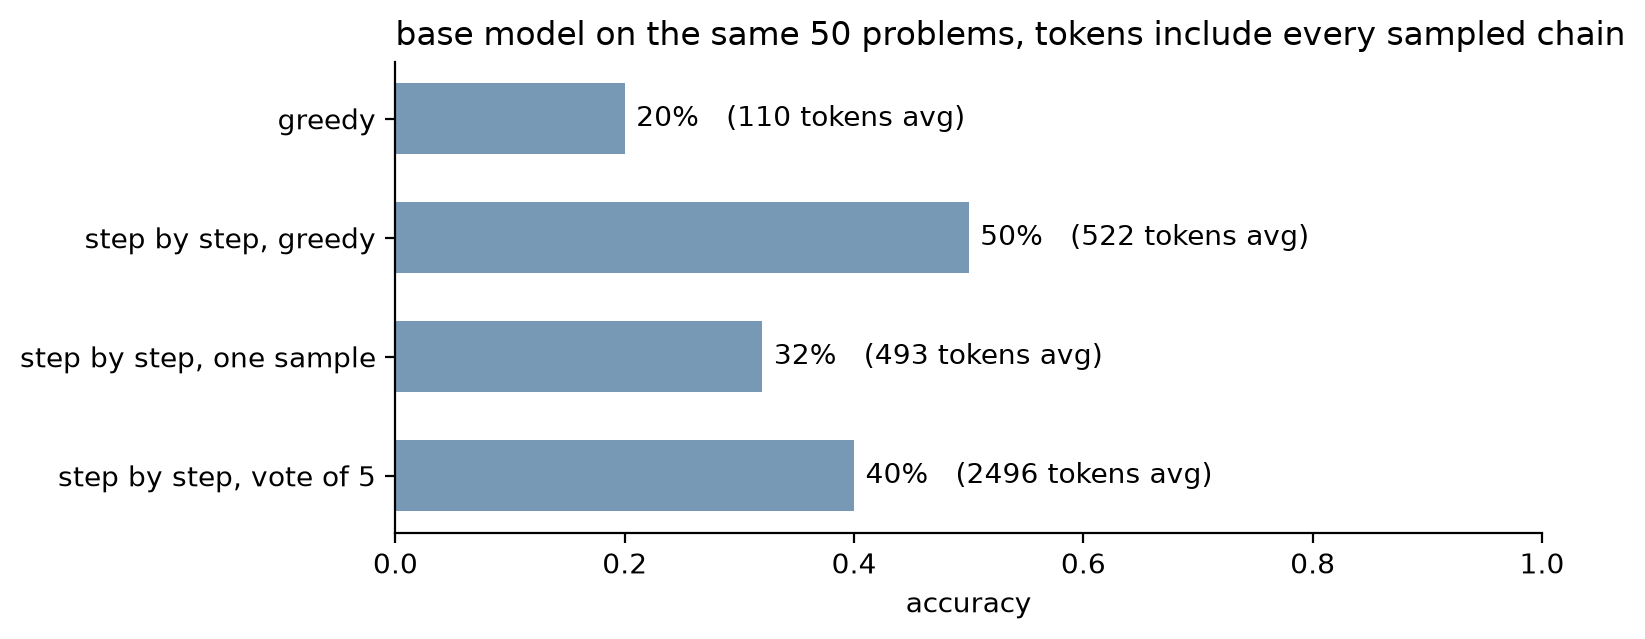

In [41]:
plot_accuracy_comparison(results, title=f"base model on the same {N} problems, tokens include every sampled chain")

Read the chart as cost against accuracy. Asking for the work is the big jump and costs a few hundred tokens per problem. A single sampled chain is clearly worse than the greedy one: at temperature 0.8 the draw occasionally derails a step, and one derailed step is enough to lose the answer. Voting over five chains recovers most of that loss, at five times the tokens, but on these fifty problems it did not catch the greedy chain: greedy decoding with the step-by-step prompt is a strong baseline for this model, and fifty problems move by several points from run to run. The point is in the shape, not the exact percentages.

The records from the voting run hold all five answers per problem, so the vote can be re-counted over the first one, three, or five chains without generating anything new. That gives a scaling curve from one run:

In [42]:
records = results["step by step, vote of 5"]["records"]
sizes = [1, 3, 5]

accuracies = []
for k in sizes:
    n_correct = sum(grade(majority_vote(r["answers"][:k])[0], r["answer"]) for r in records)
    accuracies.append(n_correct / len(records))
    print(k, "chains:", n_correct, "of", len(records))

1 chains: 13 of 50
3 chains: 16 of 50
5 chains: 20 of 50


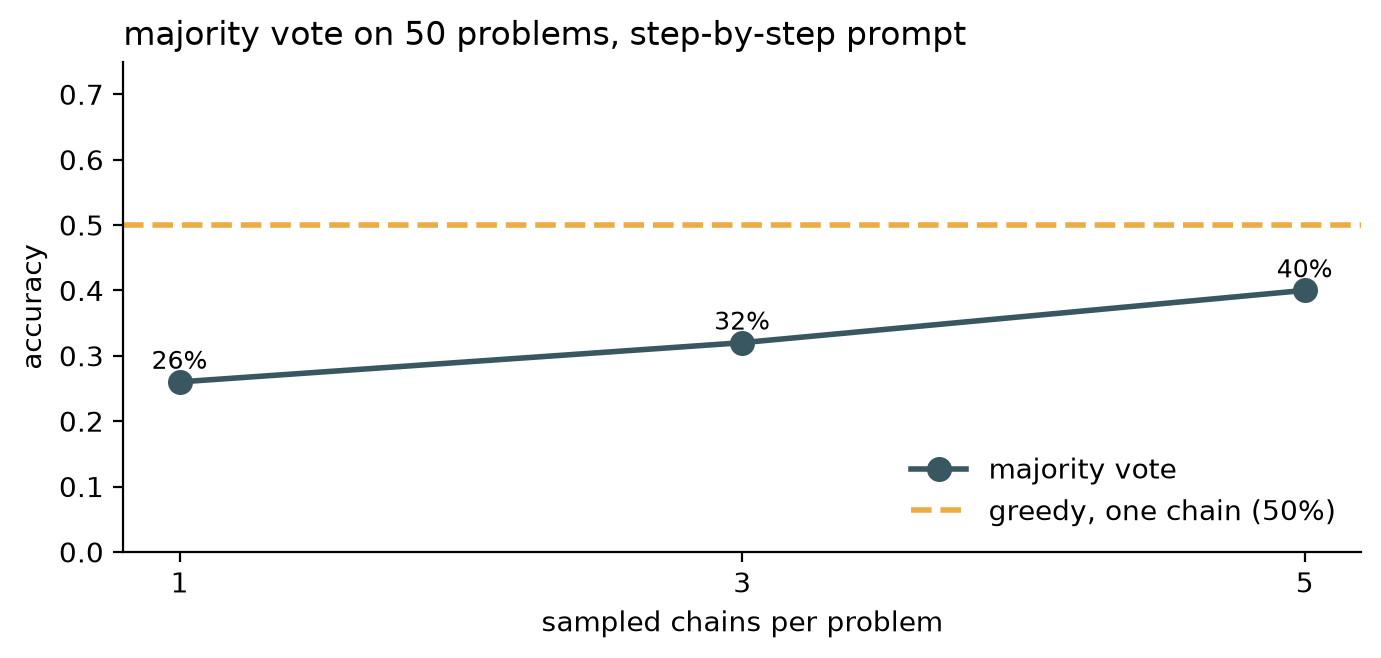

In [43]:
plot_accuracy_vs_samples(sizes, accuracies, baseline=results["step by step, greedy"]["accuracy"], title=f"majority vote on {N} problems, step-by-step prompt")

Each chain added to the vote buys a few points. The gain does not go on forever: published sweeps show it shrinking with every extra chain, and the method can only amplify what the chains already know. A problem that every chain gets wrong stays wrong however many you sample. That ceiling is why the training stages of this track exist. Sampling several solutions and checking each one is also exactly the data that reinforcement learning consumes, which makes this notebook the bridge to the next stage.

Compare the one-chain point of this curve with the single-sample bar above: same settings, different random draws, and the two numbers can differ by several points. Fifty problems give a clear picture of the ordering and only a rough estimate of each number. `scripts/evaluate_math500.py --compile --cot --temperature 0.8 --top-p 0.9 --n-samples 5` runs the full set.

## `Step 9`: Promote it to the toolbox

`scale_by_temperature`, `top_p_filter`, and the extended `generate_tokens` and `generate_text` now live in `reasoning_utils/generate.py`, exactly as written above, so the greedy loop every other notebook imports is this one with `temperature=0.0`. `majority_vote` and `self_consistency` live in `reasoning_utils/voting.py`, and `COT_PROMPT` next to `MATH_PROMPT` in `evaluate.py`. The training notebooks import all of them.

In [44]:
from reasoning_utils import COT_PROMPT as COT_PROMPT_TOOLBOX
from reasoning_utils import majority_vote as majority_vote_toolbox

print(COT_PROMPT_TOOLBOX == COT_PROMPT)
print(majority_vote_toolbox(vote["answers"]) == majority_vote(vote["answers"]))

True
True


## Summary

- Inference-time scaling trades tokens for accuracy with frozen weights. The verifier from the previous notebook scores every variant on equal terms.
- One sentence asking for the work turns a base model's guess into a worked solution. It is the single largest gain in this notebook.
- Sampling draws the next token from the softmax instead of taking its maximum. Temperature sets how spread out the distribution is; top-p drops the tail where nonsense lives. Together they are one new block inside the decoding loop.
- Self-consistency samples several chains and keeps the majority answer, pooling answers the verifier considers equivalent. It amplifies reasoning chains and does nothing for guesses.
- Every extra chain costs a full generation and buys a little accuracy, and voting cannot fix a problem every chain gets wrong. Changing the weights is the next step.

## Further reading

- [Chain-of-Thought Prompting Elicits Reasoning in Large Language Models](https://arxiv.org/abs/2201.11903) (Wei et al., 2022) and [Large Language Models are Zero-Shot Reasoners](https://arxiv.org/abs/2205.11916) (Kojima et al., 2022), on asking for the work
- [Self-Consistency Improves Chain of Thought Reasoning in Language Models](https://arxiv.org/abs/2203.11171) (Wang et al., 2022), the voting method
- [The Curious Case of Neural Text Degeneration](https://arxiv.org/abs/1904.09751) (Holtzman et al., 2019), which introduced top-p sampling
- [Large Language Monkeys: Scaling Inference Compute with Repeated Sampling](https://arxiv.org/abs/2407.21787) (Brown et al., 2024), on how far repeated sampling goes
- [Scaling LLM Test-Time Compute Optimally Can Be More Effective Than Scaling Model Parameters](https://arxiv.org/abs/2408.03314) (Snell et al., 2024)
- [`torch.multinomial`](https://docs.pytorch.org/docs/stable/generated/torch.multinomial.html) and [`torch.softmax`](https://docs.pytorch.org/docs/stable/generated/torch.nn.functional.softmax.html) documentation

Next up in this track: self-refinement, where the model critiques and rewrites its own answer, and then training with reinforcement learning.